# Real-Time Fraud Detection — Fine-Tuned Hinglish Transformer (ICFD-31k)
**Hemanth M (`1AT24CS074`) · Review 2 · Supervised model track · runs on Kaggle GPU T4 × 2**

### Why this notebook exists
All four unsupervised detectors (Isolation Forest, Mahalanobis, One-Class SVM, Deep Autoencoder) scored ROC-AUC ≈ 0.51 on the shared PCA-40 features. A diagnosis showed the fraud signal *is* in the data, but it is a **"has the scam request happened yet?"** signal (OTP / PIN / card-number requests, threats, urgency) that a model only learns **with labels**. The ICFD-31k authors (Ahuja, Prateek & Singh, IJCAI 2026) reached 95.6 % streaming F1 by **fine-tuning RoBERTa on per-chunk labels**. This notebook follows that recipe, adapted for Hinglish and for our course rules.

### Design (research-backed)
| Decision | Choice | Reason |
|---|---|---|
| Backbone | Bake-off: `FacebookAI/xlm-roberta-base`, `l3cube-pune/hing-roberta`, `google/muril-base-cased` → keep the best on validation | HingRoBERTa (XLM-R further pre-trained on Roman-script Hinglish) leads code-mixed benchmarks; MuRIL is the main Indian-language alternative; XLM-R is the multilingual default |
| Input | `cumulative_text` with speaker tags (`Agent: … Customer: …`) — the only text field | Same input as the paper's streaming model (M2) |
| Long calls (> 512 tokens) | **Head + tail truncation**: first 128 + last 382 tokens | Keeps who-is-calling + the most recent turns (where the scam ask appears); best strategy in Sun et al. 2019 |
| Labels | Per-chunk verdict (`final_verdict` of each 3-second chunk: NO before the scam ask, YES after) | Same as the paper's M2 |
| Training | lr 2e-5, effective batch 16, linear warm-up 6 %, weight-decay 0.01, fp16, early stopping on validation ROC-AUC | Paper's hyper-parameters (lr 2e-5, batch 16, early stopping) |
| 2 GPUs | **PyTorch DDP via `torchrun`** (one process per T4) | Reliable multi-GPU on Kaggle; in-process DataParallel/notebook launchers often fall back to 1 GPU |
| ≤ 50-feature rule | Fine-tuned 768-d text features + audio/time features (> 50) → `StandardScaler` → **PCA (≤ 50 comps, chosen on validation)** → Logistic Regression | Teacher's rule: if features > 50, apply PCA. The PCA model is the **official** model; the raw transformer head is reported only as a reference |
| Leakage | Only `cumulative_text`, `cumulative_audio_analysis_json`, `chunk_timestamp` are inputs. `slow_thinking_rationale`, `case_type`, `scenario_*`, `domain`, `final_verdict` are **never** model inputs | Annotation fields would reveal the answer |
| Splits | Official HF train / validation / test. Train calls split 90 % (fine-tune) / 10 % (PCA + classifier fit), by `conversation_uid` | The classifier must be fitted on chunks the transformer has not memorised |

**Saved for reuse (no retraining):** fine-tuned weights (fp16 safetensors + tokenizer) and the PCA head (`.joblib`) in `outputs/models/`, plus a `load_fraud_detector()` / `predict_fraud()` helper (Section 10).

## Section 0: Configuration
`SMOKE = True` runs the whole notebook on a tiny subset in a few minutes (used to test the pipeline before the full run).

In [1]:
SMOKE = False  # papermill parameter: True = tiny end-to-end test run

In [2]:
# Parameters
SMOKE = False


In [3]:
import gc
import json
import os
import random
import subprocess
import sys
import tempfile
import threading
import time
from pathlib import Path

import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import torch
import torch.nn as nn
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.preprocessing import OneHotEncoder, StandardScaler

try:
    import transformers, datasets  # noqa: F401
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "transformers", "datasets", "accelerate"], check=True)
import transformers
from datasets import Dataset
from transformers import AutoModelForSequenceClassification, AutoTokenizer
from huggingface_hub import snapshot_download

RANDOM_SEED = 42
CANDIDATE_MODELS = ["FacebookAI/xlm-roberta-base", "l3cube-pune/hing-roberta", "google/muril-base-cased"]
MAX_LEN = 512                 # transformer input limit (tokens, incl. special tokens)
HEAD_TOKENS = 128             # head+tail truncation: keep first 128 + last (MAX_LEN-2-128) tokens
LEARNING_RATE = 2e-5
PER_DEVICE_BATCH = 8          # x 2 GPUs = effective batch 16 (paper setting)
NUM_EPOCHS = 2
EARLY_STOP_PATIENCE = 3       # evaluations without ROC-AUC improvement
HEAD_FRACTION = 0.10          # share of TRAIN calls kept out of fine-tuning, used to fit PCA + classifier
PCA_GRID = [10, 20, 30, 40, 50]   # teacher's rule: <= 50 features after PCA
TOP_N_EMOTIONS = 12

if SMOKE:
    CALLS_PER_SPLIT, FT_TRAIN_MAX, VAL_EVAL_MAX = 80, 400, 200
    BAKEOFF_TRAIN, BAKEOFF_EVAL, BAKEOFF_STEPS, FULL_MAX_STEPS, EVAL_STEPS = 120, 100, 3, 12, 6
else:
    CALLS_PER_SPLIT, FT_TRAIN_MAX, VAL_EVAL_MAX = None, 160_000, 12_000
    BAKEOFF_TRAIN, BAKEOFF_EVAL, BAKEOFF_STEPS, FULL_MAX_STEPS, EVAL_STEPS = 24_000, 6_000, None, None, 2_000

def seed_everything(seed=RANDOM_SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
seed_everything()

N_GPUS = torch.cuda.device_count()
BASE_DIR = Path(".")
MODEL_OUT_DIR = BASE_DIR / "outputs" / "models"
MODEL_SLUG = "finetuned_transformer"
FINAL_MODEL_DIR = MODEL_OUT_DIR / MODEL_SLUG                  # fp16 weights + tokenizer (large, not for git)
WORK_DIR = Path(tempfile.gettempdir()) / "hinglish_transformer"  # tokenized data + checkpoints (temporary)
for d in [MODEL_OUT_DIR, WORK_DIR]:
    d.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "axes.grid": True, "grid.alpha": 0.25})

print(f"SMOKE run          : {SMOKE}")
print(f"GPUs visible       : {N_GPUS} -> " + ", ".join(torch.cuda.get_device_name(i) for i in range(N_GPUS)) if N_GPUS else "GPUs visible       : 0 (CPU only - training will be very slow)")
print(f"transformers       : {transformers.__version__} | torch {torch.__version__}")
print(f"Candidates         : {CANDIDATE_MODELS}")
print(f"Max length / head  : {MAX_LEN} / {HEAD_TOKENS} | lr {LEARNING_RATE} | batch {PER_DEVICE_BATCH} x {max(N_GPUS,1)} GPU(s)")

SMOKE run          : False
GPUs visible       : 2 -> Tesla T4, Tesla T4
transformers       : 5.20.2 | torch 2.11.0+cu130
Candidates         : ['FacebookAI/xlm-roberta-base', 'l3cube-pune/hing-roberta', 'google/muril-base-cased']
Max length / head  : 512 / 128 | lr 2e-05 | batch 8 x 2 GPU(s)


## Section 1: Locate & Load ICFD-31k (official v1.0 streaming chunks)
Looks for the data in `data/icfd-31k/` (local clone), then in attached Kaggle inputs, and only then downloads from Hugging Face (the HF repo is **gated**: it needs a logged-in account with access, e.g. `HF_TOKEN`).
Only the columns below are read. **Model inputs:** `cumulative_text`, `cumulative_audio_analysis_json`, `chunk_timestamp`. **Labels / grouping only:** `final_verdict`, `conversation_uid`, `domain`.

In [4]:
LOAD_COLS = ["conversation_uid", "domain", "chunk_timestamp", "final_verdict", "cumulative_text", "cumulative_audio_analysis_json"]
MODEL_INPUT_COLS = ["cumulative_text", "cumulative_audio_analysis_json", "chunk_timestamp"]
NEVER_INPUT_COLS = ["final_verdict", "slow_thinking_rationale", "case_type", "domain", "scenario_info_json",
                    "scenario_id", "combination_key", "conversation_uid", "session_id"]
assert not set(MODEL_INPUT_COLS) & set(NEVER_INPUT_COLS)

def locate_data_dir():
    local = BASE_DIR / "data" / "icfd-31k"
    if (local / "release_summary.json").exists():
        return local
    if Path("/kaggle/input").exists():
        hits = sorted(Path("/kaggle/input").rglob("release_summary.json"))
        if hits:
            return hits[0].parent
    print("Downloading rishia2220/icfd-31k from Hugging Face (gated: requires access + login)...")
    snapshot_download(repo_id="rishia2220/icfd-31k", repo_type="dataset", local_dir=str(local),
                      allow_patterns=["streaming_chunks/*", "release_summary.json"])
    return local

DATA_DIR = locate_data_dir()
SHARDS = {s: sorted(DATA_DIR.rglob(f"{s}-*.parquet")) for s in ("train", "validation", "test")}
print("Data directory:", DATA_DIR.resolve(), {k: len(v) for k, v in SHARDS.items()})
assert all(SHARDS.values()), "Missing parquet shards"

def load_split(files):
    df = pq.read_table(files, columns=LOAD_COLS).to_pandas()
    return df.sort_values(["conversation_uid", "chunk_timestamp"], kind="stable").reset_index(drop=True)

raw = {s: load_split(f) for s, f in SHARDS.items()}

if SMOKE:  # keep a few legit + fraud calls per split so every metric is defined
    for s, df in raw.items():
        last = df.groupby("conversation_uid")["final_verdict"].last().astype(str).str.strip().str.upper()
        k = CALLS_PER_SPLIT // 2
        keep = list(last[last == "NO"].index[:k]) + list(last[last != "NO"].index[:k])
        raw[s] = df[df["conversation_uid"].isin(keep)].reset_index(drop=True)

for s, df in raw.items():
    print(f"{s:<11}: {len(df):>9,} chunks | {df['conversation_uid'].nunique():>6,} calls")

Data directory: /kaggle/input/datasets/hemanthm2006/icfd31k-streaming-chunks {'train': 50, 'validation': 8, 'test': 8}


train      :   712,316 chunks | 20,996 calls
validation :   173,813 chunks |  4,499 calls
test       :   179,827 chunks |  4,499 calls


## Section 2: Cleaning & Label Definition
* **Label `y`** = verdict of each 3-second chunk (`YES` → 1). A scam call is labelled 0 before the scam request and 1 after it.
* **Text** = `cumulative_text` with speaker tags kept, extra spaces collapsed.
* **Audio/time features** parsed from `cumulative_audio_analysis_json` (dominant/secondary emotion, pace, confidence) + `chunk_timestamp`.

In [5]:
PACE_MAP = {"slow": 0.0, "medium": 1.0, "fast": 2.0}

def parse_audio(val):
    if isinstance(val, dict):
        return val
    if val is None or (isinstance(val, float) and np.isnan(val)):
        return {}
    try:
        out = json.loads(str(val))
        return out if isinstance(out, dict) else {}
    except (json.JSONDecodeError, TypeError):
        return {}

def clean_split(df):
    audio = pd.DataFrame([parse_audio(v) for v in df["cumulative_audio_analysis_json"]])
    get = lambda col, default: audio[col] if col in audio.columns else pd.Series(default, index=audio.index)
    out = pd.DataFrame({
        "conversation_uid": df["conversation_uid"].astype(str).to_numpy(),
        "domain": df["domain"].astype(str).to_numpy(),
        "chunk_timestamp": pd.to_numeric(df["chunk_timestamp"], errors="coerce").fillna(0.0).clip(lower=0.0).astype(np.float32).to_numpy(),
        "y": (df["final_verdict"].fillna("NO").astype(str).str.strip().str.upper() == "YES").astype(np.int8).to_numpy(),
        "text": df["cumulative_text"].fillna("").astype(str).str.replace(r"[ \t]+", " ", regex=True).str.strip().to_numpy(),
        "dominant_emotion": get("dominant_emotion", "Unknown").fillna("Unknown").astype(str).str.strip().replace("", "Unknown").to_numpy(),
        "secondary_emotion": get("secondary_emotion", "Unknown").fillna("Unknown").astype(str).str.strip().replace("", "Unknown").to_numpy(),
        "pace_num": get("pace", np.nan).astype(str).str.strip().str.lower().map(PACE_MAP).astype(np.float32).to_numpy(),
        "confidence_score": pd.to_numeric(get("confidence_score", np.nan), errors="coerce").clip(0, 1).astype(np.float32).to_numpy(),
        "audio_json": df["cumulative_audio_analysis_json"].to_numpy(dtype=object),
    })
    return out

data = {s: clean_split(df) for s, df in raw.items()}
del raw; gc.collect()

for s, d in data.items():
    calls = d.groupby("conversation_uid")["y"].agg(["last", "max", "min"])
    flips = d[d["y"] == 1].groupby("conversation_uid")["chunk_timestamp"].min()
    print(f"{s:<11}: fraud-chunk rate {d['y'].mean():.3f} | legit calls {(calls['last']==0).sum():,} | fraud calls {(calls['last']==1).sum():,} "
          f"| median label flip at {flips.median():.0f}s | empty texts {(d['text']=='').sum():,}")

train      : fraud-chunk rate 0.209 | legit calls 15,178 | fraud calls 5,818 | median label flip at 38s | empty texts 0
validation : fraud-chunk rate 0.658 | legit calls 49 | fraud calls 4,450 | median label flip at 39s | empty texts 0
test       : fraud-chunk rate 0.640 | legit calls 49 | fraud calls 4,450 | median label flip at 45s | empty texts 0


## Section 3: Leakage-Free Splits
Train calls are split **by `conversation_uid`** into a fine-tuning part (90 %) and a held-out *head* part (10 %) used only to fit the scaler, PCA and the final classifier. Validation is used for early stopping, backbone selection, PCA size and thresholds. **Test is touched once, at the end.**

In [6]:
train_uids = np.array(sorted(data["train"]["conversation_uid"].unique()))
perm = np.random.default_rng(RANDOM_SEED).permutation(train_uids)
n_head = max(1, int(round(HEAD_FRACTION * len(perm))))
head_uids = set(perm[:n_head])
ft_df = data["train"][~data["train"]["conversation_uid"].isin(head_uids)].reset_index(drop=True)
head_df = data["train"][data["train"]["conversation_uid"].isin(head_uids)].reset_index(drop=True)
val_df, test_df = data["validation"], data["test"]
assert not (set(ft_df.conversation_uid) & set(head_df.conversation_uid))
assert not (set(data["train"].conversation_uid) & set(val_df.conversation_uid)) and not (set(val_df.conversation_uid) & set(test_df.conversation_uid))

# Fine-tuning set: identical (text, label) pairs (silence/pause chunks) are kept once, then capped for time
ft_unique = ft_df.drop_duplicates(subset=["text", "y"]).reset_index(drop=True)
ft_train = ft_unique.sample(n=min(FT_TRAIN_MAX, len(ft_unique)), random_state=RANDOM_SEED).reset_index(drop=True)
val_unique = val_df.drop_duplicates(subset=["text", "y"])
val_eval = val_unique.sample(n=min(VAL_EVAL_MAX, len(val_unique)), random_state=RANDOM_SEED).reset_index(drop=True)

print(f"Fine-tune calls : {ft_df.conversation_uid.nunique():,} ({len(ft_df):,} chunks -> {len(ft_unique):,} unique -> {len(ft_train):,} used, fraud rate {ft_train.y.mean():.3f})")
print(f"Head calls      : {head_df.conversation_uid.nunique():,} ({len(head_df):,} chunks) -> PCA + classifier fit")
print(f"Validation      : {len(val_df):,} chunks (in-training eval subset: {len(val_eval):,}, fraud rate {val_eval.y.mean():.3f})")
print(f"Test            : {len(test_df):,} chunks (held out until Section 9)")

Fine-tune calls : 18,896 (639,987 chunks -> 228,584 unique -> 160,000 used, fraud rate 0.206)
Head calls      : 2,100 (72,329 chunks) -> PCA + classifier fit
Validation      : 173,813 chunks (in-training eval subset: 12,000, fraud rate 0.654)
Test            : 179,827 chunks (held out until Section 9)


## Section 4: Tokenisation with Head + Tail Truncation
Texts longer than the limit keep their first 128 tokens (greeting, who is calling) and their **most recent** tokens (where a scam request appears).

In [7]:
def special_token_template(tok):
    # Works on every transformers version: compare a probe encoded with and without special tokens
    probe = "namaste hello world"
    with_sp = tok(probe)["input_ids"]
    without = tok(probe, add_special_tokens=False)["input_ids"]
    for i in range(len(with_sp) - len(without) + 1):
        if with_sp[i:i + len(without)] == without:
            return with_sp[:i], with_sp[i + len(without):]
    raise ValueError("Could not infer the special-token template")

def encode_head_tail(tok, texts, max_len=MAX_LEN, head=HEAD_TOKENS):
    prefix, suffix = special_token_template(tok)   # e.g. <s> ... </s> (XLM-R) or [CLS] ... [SEP] (BERT/MuRIL)
    body = max_len - len(prefix) - len(suffix)
    ids_all = tok(list(texts), add_special_tokens=False, truncation=False)["input_ids"]
    out, n_trunc = [], 0
    for ids in ids_all:
        if len(ids) > body:
            ids = ids[:head] + ids[-(body - head):]
            n_trunc += 1
        out.append(prefix + list(ids) + suffix)
    return out, n_trunc

def build_dataset(tok, df, path):
    ids, n_trunc = encode_head_tail(tok, df["text"].tolist())
    ds = Dataset.from_dict({"input_ids": ids, "attention_mask": [[1] * len(x) for x in ids],
                            "labels": df["y"].astype(int).tolist(), "length": [len(x) for x in ids]})
    ds.save_to_disk(str(path))
    return ds, n_trunc

def prepare_model_data(model_name, train_df, eval_df, tag):
    tok = AutoTokenizer.from_pretrained(model_name)  # download once, before the training processes start
    _warm = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=2); del _warm; gc.collect()
    tr_path, ev_path = WORK_DIR / f"{tag}_train", WORK_DIR / f"{tag}_eval"
    tr, n1 = build_dataset(tok, train_df, tr_path)
    ev, n2 = build_dataset(tok, eval_df, ev_path)
    lens = np.array(tr["length"])
    print(f"[{model_name}] train {len(tr):,} (truncated {n1:,}) | eval {len(ev):,} (truncated {n2:,}) | "
          f"tokens median {np.median(lens):.0f}, p90 {np.percentile(lens, 90):.0f}")
    return tr_path, ev_path

## Section 5: Multi-GPU Fine-Tuning Script (PyTorch DDP)
The training code is written to a script and launched with **`torchrun --nproc_per_node=<#GPUs>`** — one process per T4, gradients synchronised by DistributedDataParallel (Hugging Face `Trainer` switches to DDP automatically under `torchrun`).

In [8]:
TRAIN_SCRIPT = WORK_DIR / "train_ddp.py"
TRAIN_SCRIPT.write_text(r"""
import argparse, inspect, json, math, os
import numpy as np
import torch
from datasets import load_from_disk
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score
from transformers import (AutoModelForSequenceClassification, AutoTokenizer, DataCollatorWithPadding,
                          EarlyStoppingCallback, Trainer, TrainingArguments, set_seed)

p = argparse.ArgumentParser()
p.add_argument("--model_name", required=True)
p.add_argument("--train_dir", required=True)
p.add_argument("--eval_dir", required=True)
p.add_argument("--ckpt_dir", required=True)
p.add_argument("--save_dir", default="")
p.add_argument("--metrics_out", required=True)
p.add_argument("--epochs", type=float, default=2.0)
p.add_argument("--max_steps", type=int, default=-1)
p.add_argument("--lr", type=float, default=2e-5)
p.add_argument("--batch", type=int, default=8)
p.add_argument("--eval_steps", type=int, default=2000)
p.add_argument("--patience", type=int, default=3)
p.add_argument("--seed", type=int, default=42)
p.add_argument("--bakeoff", action="store_true")
a = p.parse_args()
set_seed(a.seed)

tok = AutoTokenizer.from_pretrained(a.model_name)
train_ds, eval_ds = load_from_disk(a.train_dir), load_from_disk(a.eval_dir)
model = AutoModelForSequenceClassification.from_pretrained(a.model_name, num_labels=2)

def compute_metrics(ev):
    logits, labels = ev.predictions, ev.label_ids
    logits = logits[0] if isinstance(logits, (tuple, list)) else logits
    prob = torch.softmax(torch.tensor(np.asarray(logits), dtype=torch.float32), dim=-1)[:, 1].numpy()
    pred = (prob >= 0.5).astype(int)
    auc = roc_auc_score(labels, prob) if len(np.unique(labels)) > 1 else float("nan")
    return {"roc_auc": float(auc), "f1": float(f1_score(labels, pred, zero_division=0)),
            "precision": float(precision_score(labels, pred, zero_division=0)),
            "recall": float(recall_score(labels, pred, zero_division=0))}

sig = set(inspect.signature(TrainingArguments.__init__).parameters)
strategy_key = "eval_strategy" if "eval_strategy" in sig else "evaluation_strategy"
world = int(os.environ.get("WORLD_SIZE", "1"))
steps_per_epoch = math.ceil(len(train_ds) / (a.batch * world))
total_steps = a.max_steps if a.max_steps > 0 else math.ceil(steps_per_epoch * a.epochs)
warmup_steps = max(1, int(0.06 * total_steps))   # 6 % linear warm-up (explicit: works on every transformers version)
kw = dict(output_dir=a.ckpt_dir, num_train_epochs=a.epochs, max_steps=a.max_steps, learning_rate=a.lr,
          per_device_train_batch_size=a.batch, per_device_eval_batch_size=a.batch * 4, gradient_accumulation_steps=1,
          warmup_steps=warmup_steps, weight_decay=0.01, lr_scheduler_type="linear", fp16=torch.cuda.is_available(),
          logging_steps=200, report_to="none", seed=a.seed, data_seed=a.seed, group_by_length=True,
          length_column_name="length", dataloader_num_workers=2, ddp_find_unused_parameters=False, disable_tqdm=True)
if a.bakeoff:
    kw.update({strategy_key: "no", "save_strategy": "no"})
else:
    kw.update({strategy_key: "steps", "eval_steps": a.eval_steps, "save_strategy": "steps", "save_steps": a.eval_steps,
               "save_total_limit": 2, "save_only_model": True, "load_best_model_at_end": True,
               "metric_for_best_model": "roc_auc", "greater_is_better": True})
dropped = sorted(k for k in kw if k not in sig)
kw = {k: v for k, v in kw.items() if k in sig}
for must in ("output_dir", "learning_rate", "fp16", "per_device_train_batch_size", "warmup_steps", "weight_decay"):
    assert must in kw, must
args = TrainingArguments(**kw)
callbacks = [] if a.bakeoff else [EarlyStoppingCallback(early_stopping_patience=a.patience)]
trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=eval_ds,
                  data_collator=DataCollatorWithPadding(tok), compute_metrics=compute_metrics, callbacks=callbacks)
if trainer.is_world_process_zero():
    print(f"world_size={args.world_size} | n_gpu/process={args.n_gpu} | fp16={args.fp16} | train={len(train_ds)} | total_steps={total_steps} | warmup_steps={warmup_steps} | dropped unsupported args: {dropped}", flush=True)
train_out = trainer.train()
final_eval = trainer.evaluate()
if trainer.is_world_process_zero():
    if a.save_dir:
        trainer.save_model(a.save_dir)
        tok.save_pretrained(a.save_dir)
    json.dump({"model_name": a.model_name, "world_size": args.world_size, "train_runtime_sec": train_out.metrics.get("train_runtime"),
               "global_step": trainer.state.global_step, "best_metric": trainer.state.best_metric,
               "best_checkpoint": trainer.state.best_model_checkpoint, "final_eval": final_eval,
               "log_history": trainer.state.log_history}, open(a.metrics_out, "w"), indent=2, default=str)
    print("FINAL_EVAL", json.dumps(final_eval), flush=True)
""")

def run_ddp(model_name, train_dir, eval_dir, tag, save_dir="", epochs=NUM_EPOCHS, max_steps=None, bakeoff=False):
    metrics_out = WORK_DIR / f"{tag}_metrics.json"
    nproc = max(N_GPUS, 1)
    cmd = [sys.executable, "-m", "torch.distributed.run", f"--nproc_per_node={nproc}", "--master_port=29531",
           str(TRAIN_SCRIPT), "--model_name", model_name, "--train_dir", str(train_dir), "--eval_dir", str(eval_dir),
           "--ckpt_dir", str(WORK_DIR / f"{tag}_ckpt"), "--metrics_out", str(metrics_out), "--epochs", str(epochs),
           "--max_steps", str(max_steps if max_steps else -1), "--lr", str(LEARNING_RATE), "--batch", str(PER_DEVICE_BATCH),
           "--eval_steps", str(EVAL_STEPS), "--patience", str(EARLY_STOP_PATIENCE), "--seed", str(RANDOM_SEED)]
    if save_dir:
        cmd += ["--save_dir", str(save_dir)]
    if bakeoff:
        cmd += ["--bakeoff"]
    env = {**os.environ, "TOKENIZERS_PARALLELISM": "false", "OMP_NUM_THREADS": "2", "PYTHONUNBUFFERED": "1"}
    t0 = time.time()
    proc = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, env=env)
    tail = []
    for line in proc.stdout:  # stream training logs into the notebook
        tail = (tail + [line.rstrip()])[-80:]
        if any(k in line for k in ("'loss'", '"loss"', "'eval_", '"eval_', "world_size", "FINAL_EVAL", "train_runtime")):
            print(line.rstrip(), flush=True)
    if proc.wait() != 0:
        print(chr(10).join(tail))
        raise RuntimeError(f"torchrun failed for {model_name} (exit {proc.returncode})")
    out = json.load(open(metrics_out))
    print(f"[{tag}] done in {(time.time()-t0)/60:.1f} min on {out['world_size']} process(es) | final eval: "
          + ", ".join(f"{k}={v:.4f}" for k, v in out["final_eval"].items() if k in ("eval_roc_auc", "eval_f1")))
    return out

## Section 6: Backbone Bake-off (pick the best of 3 multilingual transformers)
Each candidate is fine-tuned on the same 24k-chunk subset for one epoch and scored on the same 6k validation chunks. The highest validation **ROC-AUC** wins.

In [9]:
bake_train = ft_train.sample(n=min(BAKEOFF_TRAIN, len(ft_train)), random_state=RANDOM_SEED)
bake_eval = val_eval.sample(n=min(BAKEOFF_EVAL, len(val_eval)), random_state=RANDOM_SEED)
bakeoff = []
for i, name in enumerate(CANDIDATE_MODELS):
    print(f"\n===== Bake-off {i+1}/{len(CANDIDATE_MODELS)}: {name} =====")
    try:
        tr_dir, ev_dir = prepare_model_data(name, bake_train, bake_eval, tag=f"bake{i}")
        res = run_ddp(name, tr_dir, ev_dir, tag=f"bake{i}", epochs=1, max_steps=BAKEOFF_STEPS, bakeoff=True)
        bakeoff.append({"model": name, "val_roc_auc": res["final_eval"].get("eval_roc_auc"), "val_f1": res["final_eval"].get("eval_f1"),
                        "minutes": round((res.get("train_runtime_sec") or 0) / 60, 1)})
    except Exception as e:
        print(f"!! {name} failed and is skipped: {type(e).__name__}: {e}")
        bakeoff.append({"model": name, "val_roc_auc": float("nan"), "val_f1": float("nan"), "error": str(e)[:300]})

bakeoff_df = pd.DataFrame(bakeoff).sort_values("val_roc_auc", ascending=False)
print("\n=== Backbone bake-off (validation subset) ===")
print(bakeoff_df.to_string(index=False))
assert bakeoff_df["val_roc_auc"].notna().any(), "All candidates failed"
BEST_BACKBONE = bakeoff_df.iloc[0]["model"]
print(f"\nSelected backbone: {BEST_BACKBONE}")


===== Bake-off 1/3: FacebookAI/xlm-roberta-base =====


config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

... (68 outputs left out)

{'train_runtime': '609.1', 'train_samples_per_second': '39.4', 'train_steps_per_second': '2.462', 'train_loss': '0.869', 'epoch': '1'}


{'eval_loss': '1.635', 'eval_roc_auc': '0.8445', 'eval_f1': '0.7613', 'eval_precision': '0.8909', 'eval_recall': '0.6646', 'eval_runtime': '22.82', 'eval_samples_per_second': '262.9', 'eval_steps_per_second': '4.118', 'epoch': '1'}


FINAL_EVAL {"eval_loss": 1.6350250244140625, "eval_roc_auc": 0.84453923489371, "eval_f1": 0.7613222659094219, "eval_precision": 0.89093387866394, "eval_recall": 0.6646325959827104, "eval_runtime": 22.8247, "eval_samples_per_second": 262.873, "eval_steps_per_second": 4.118, "epoch": 1.0}


[bake2] done in 10.8 min on 2 process(es) | final eval: eval_roc_auc=0.8445, eval_f1=0.7613

=== Backbone bake-off (validation subset) ===
                      model  val_roc_auc   val_f1  minutes
   l3cube-pune/hing-roberta     0.891112 0.832169     11.6
FacebookAI/xlm-roberta-base     0.862874 0.812259     11.6
    google/muril-base-cased     0.844539 0.761322     10.2

Selected backbone: l3cube-pune/hing-roberta


## Section 7: Full Fine-Tuning of the Selected Backbone on 2 GPUs
Early stopping on validation ROC-AUC; the best checkpoint is restored and saved.

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: l3cube-pune/hing-roberta
Key                        | Status     | 
---------------------------+------------+-
lm_head.bias               | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (556 > 512). Running this sequence through the model will result in indexing errors


Saving the dataset (0/1 shards):   0%|          | 0/160000 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/12000 [00:00<?, ? examples/s]

[l3cube-pune/hing-roberta] train 160,000 (truncated 7,214) | eval 12,000 (truncated 744) | tokens median 192, p90 415


... (48 outputs left out)

[full] done in 65.8 min on 2 process(es) | final eval: eval_roc_auc=0.9013, eval_f1=0.6527


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved fine-tuned weights -> outputs/models/finetuned_transformer (573 MB)


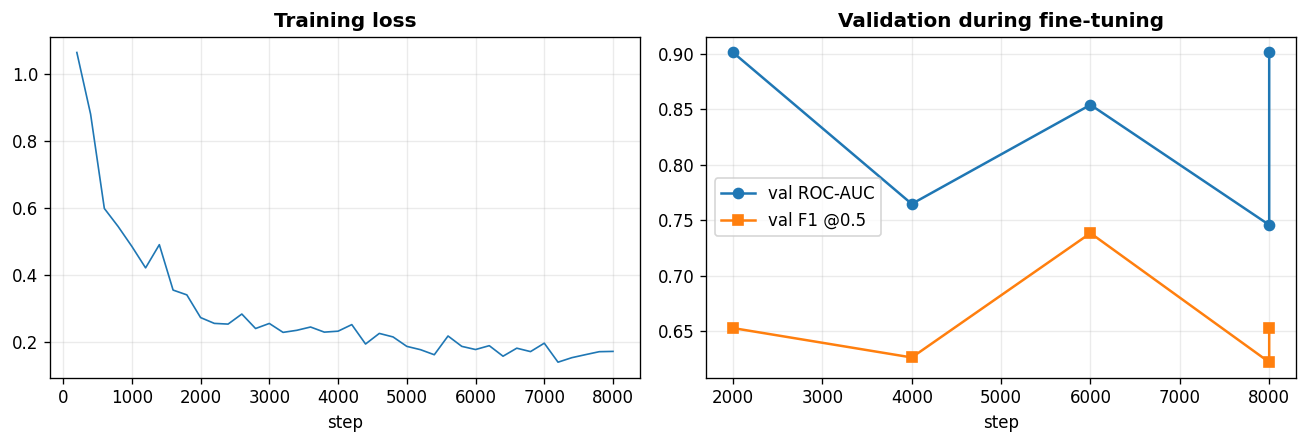

In [10]:
tr_dir, ev_dir = prepare_model_data(BEST_BACKBONE, ft_train, val_eval, tag="full")
FT_FP32_DIR = WORK_DIR / "full_best_fp32"
full_res = run_ddp(BEST_BACKBONE, tr_dir, ev_dir, tag="full", save_dir=FT_FP32_DIR, epochs=NUM_EPOCHS, max_steps=FULL_MAX_STEPS)

# Save the deployable copy in fp16 safetensors (half the size, same predictions within fp16 precision)
_m = AutoModelForSequenceClassification.from_pretrained(FT_FP32_DIR)
_m.half().save_pretrained(FINAL_MODEL_DIR)  # safetensors format (default)
AutoTokenizer.from_pretrained(FT_FP32_DIR).save_pretrained(FINAL_MODEL_DIR)
del _m; gc.collect()
size_mb = sum(f.stat().st_size for f in FINAL_MODEL_DIR.glob("*")) / 1e6
print(f"Saved fine-tuned weights -> {FINAL_MODEL_DIR} ({size_mb:.0f} MB)")

hist = pd.DataFrame([h for h in full_res["log_history"] if "eval_roc_auc" in h])
loss = pd.DataFrame([h for h in full_res["log_history"] if "loss" in h and "eval_loss" not in h])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
if len(loss):
    ax[0].plot(loss["step"], loss["loss"], lw=1); ax[0].set_title("Training loss", fontweight="bold"); ax[0].set_xlabel("step")
if len(hist):
    ax[1].plot(hist["step"], hist["eval_roc_auc"], marker="o", label="val ROC-AUC")
    ax[1].plot(hist["step"], hist["eval_f1"], marker="s", label="val F1 @0.5"); ax[1].legend()
    ax[1].set_title("Validation during fine-tuning", fontweight="bold"); ax[1].set_xlabel("step")
plt.tight_layout(); fig.savefig(MODEL_OUT_DIR / f"{MODEL_SLUG}_training_curve.png", dpi=200); plt.show()

## Section 8: Feature Extraction → PCA (≤ 50) → Classifier  *(teacher's rule)*
For every chunk we take the fine-tuned model's **768-d penultimate representation** (input of the final classification layer) and add the audio/time features (emotion one-hots, pace, confidence, timestamp). That is **> 50 features**, so we apply `StandardScaler` → **PCA** and train a **Logistic Regression** on the principal components. Everything is fitted on the held-out *head* calls only; the number of components (≤ 50) is chosen on validation. Inference runs on both GPUs in parallel (one model copy per GPU).

In [11]:
def final_linear(model):
    head = model.classifier
    if hasattr(head, "out_proj"):      # RoBERTa / XLM-R / HingRoBERTa
        return head.out_proj
    if isinstance(head, nn.Linear):    # BERT / MuRIL
        return head
    raise ValueError(f"Unknown classification head: {type(head)}")

def transformer_scores(model_dir, texts, batch_size=64):
    # Returns (P(fraud), penultimate features) for each text, using every visible GPU in parallel.
    texts = list(texts)
    tok0 = AutoTokenizer.from_pretrained(model_dir)
    ids, _ = encode_head_tail(tok0, texts)
    order = np.argsort([len(x) for x in ids], kind="stable")
    devices = [f"cuda:{i}" for i in range(N_GPUS)] or ["cpu"]
    parts = [order[i::len(devices)] for i in range(len(devices))]
    probs = np.zeros(len(texts), dtype=np.float32)
    feats = [None]
    errors = []

    def work(dev, idx):
        try:
            tok = AutoTokenizer.from_pretrained(model_dir)
            m = AutoModelForSequenceClassification.from_pretrained(model_dir)
            m = (m.half() if dev.startswith("cuda") else m.float()).to(dev).eval()
            cap = {}
            hook = final_linear(m).register_forward_hook(lambda mod, inp, out: cap.__setitem__("x", inp[0]))
            for s in range(0, len(idx), batch_size):
                b = idx[s:s + batch_size]
                enc = tok.pad({"input_ids": [ids[j] for j in b]}, return_tensors="pt")
                with torch.no_grad():
                    logits = m(input_ids=enc["input_ids"].to(dev), attention_mask=enc["attention_mask"].to(dev)).logits.float()
                probs[b] = torch.softmax(logits, dim=-1)[:, 1].cpu().numpy()
                x = cap["x"].float().cpu().numpy()
                if feats[0] is None:
                    feats[0] = np.zeros((len(texts), x.shape[1]), dtype=np.float32)
                feats[0][b] = x
            hook.remove()
            del m
        except Exception as e:  # surface thread errors
            errors.append(e)

    threads = [threading.Thread(target=work, args=(d, p)) for d, p in zip(devices, parts)]
    [t.start() for t in threads]; [t.join() for t in threads]
    if errors:
        raise errors[0]
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return probs, feats[0]

# Score every UNIQUE text once (head + validation + test), then map back to chunks
t0 = time.time()
all_text = pd.concat([head_df["text"], val_df["text"], test_df["text"]], ignore_index=True)
codes, uniques = pd.factorize(all_text, sort=False)
u_prob, u_feat = transformer_scores(FINAL_MODEL_DIR, uniques.tolist())
n1, n2 = len(head_df), len(val_df)
for d, sl in [(head_df, slice(0, n1)), (val_df, slice(n1, n1 + n2)), (test_df, slice(n1 + n2, None))]:
    d["tf_prob"] = u_prob[codes[sl]]
FEAT = {"head": u_feat[codes[:n1]], "val": u_feat[codes[n1:n1 + n2]], "test": u_feat[codes[n1 + n2:]]}
print(f"Scored {len(uniques):,} unique texts on {max(N_GPUS,1)} device(s) in {(time.time()-t0)/60:.1f} min | penultimate dim = {u_feat.shape[1]}")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (515 > 512). Running this sequence through the model will result in indexing errors


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Scored 147,798 unique texts on 2 device(s) in 4.8 min | penultimate dim = 768


In [12]:
# Audio/time features — vocabulary and imputation fitted on the head calls only
PACE_MEDIAN = float(np.nanmedian(head_df["pace_num"])) if head_df["pace_num"].notna().any() else 1.0
CONF_MEDIAN = float(np.nanmedian(head_df["confidence_score"])) if head_df["confidence_score"].notna().any() else 1.0
TOP_DOM = sorted(head_df["dominant_emotion"].value_counts().head(TOP_N_EMOTIONS).index)
TOP_SEC = sorted(head_df["secondary_emotion"].value_counts().head(TOP_N_EMOTIONS).index)

def audio_frame(d):
    return pd.DataFrame({
        "dominant_emotion": d["dominant_emotion"].where(d["dominant_emotion"].isin(TOP_DOM), "Other"),
        "secondary_emotion": d["secondary_emotion"].where(d["secondary_emotion"].isin(TOP_SEC), "Other"),
        "pace_num": d["pace_num"].fillna(PACE_MEDIAN), "confidence_score": d["confidence_score"].fillna(CONF_MEDIAN),
        "chunk_timestamp": d["chunk_timestamp"]})

OHE = OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=np.float32).fit(audio_frame(head_df)[["dominant_emotion", "secondary_emotion"]])

def full_features(text_feat, d):
    a = audio_frame(d)
    return np.hstack([text_feat, OHE.transform(a[["dominant_emotion", "secondary_emotion"]]),
                      a[["pace_num", "confidence_score", "chunk_timestamp"]].to_numpy(np.float32)]).astype(np.float32)

X_head, X_val, X_test = full_features(FEAT["head"], head_df), full_features(FEAT["val"], val_df), full_features(FEAT["test"], test_df)
y_head, y_val, y_test = head_df["y"].to_numpy(), val_df["y"].to_numpy(), test_df["y"].to_numpy()
N_RAW_FEATURES = X_head.shape[1]
print(f"Raw feature count: {N_RAW_FEATURES} (768-d text + {N_RAW_FEATURES - FEAT['head'].shape[1]} audio/time) -> more than 50, so PCA is applied")
assert N_RAW_FEATURES > 50

SCALER = StandardScaler().fit(X_head)
Xh_s, Xv_s, Xt_s = SCALER.transform(X_head), SCALER.transform(X_val), SCALER.transform(X_test)
grid = []
for n in PCA_GRID:
    n = min(n, Xh_s.shape[0] - 1, Xh_s.shape[1])
    pca_n = PCA(n_components=n, random_state=RANDOM_SEED).fit(Xh_s)
    clf_n = LogisticRegression(max_iter=5000, random_state=RANDOM_SEED).fit(pca_n.transform(Xh_s), y_head)
    auc = roc_auc_score(y_val, clf_n.predict_proba(pca_n.transform(Xv_s))[:, 1])
    grid.append({"n_components": n, "explained_var": float(pca_n.explained_variance_ratio_.sum()), "val_roc_auc": float(auc)})
    print(f"  PCA {n:>2} comps | explained variance {pca_n.explained_variance_ratio_.sum()*100:5.1f}% | val ROC-AUC {auc:.4f}")
grid_df = pd.DataFrame(grid)
best_auc = grid_df["val_roc_auc"].max()
N_COMPONENTS = int(grid_df[grid_df["val_roc_auc"] >= best_auc - 1e-3]["n_components"].min())  # smallest within 0.001 of best
assert N_COMPONENTS <= 50
PCA_MODEL = PCA(n_components=N_COMPONENTS, random_state=RANDOM_SEED).fit(Xh_s)
CLASSIFIER = LogisticRegression(max_iter=5000, random_state=RANDOM_SEED).fit(PCA_MODEL.transform(Xh_s), y_head)
print(f"\nSelected PCA size: {N_COMPONENTS} components (<= 50) | explained variance {PCA_MODEL.explained_variance_ratio_.sum()*100:.1f}%")

score_head = CLASSIFIER.predict_proba(PCA_MODEL.transform(Xh_s))[:, 1]
score_val = CLASSIFIER.predict_proba(PCA_MODEL.transform(Xv_s))[:, 1]
score_test = CLASSIFIER.predict_proba(PCA_MODEL.transform(Xt_s))[:, 1]

Raw feature count: 797 (768-d text + 29 audio/time) -> more than 50, so PCA is applied


  PCA 10 comps | explained variance  80.0% | val ROC-AUC 0.8914


  PCA 20 comps | explained variance  84.7% | val ROC-AUC 0.8821


  PCA 30 comps | explained variance  87.3% | val ROC-AUC 0.8856


  PCA 40 comps | explained variance  89.3% | val ROC-AUC 0.8824


  PCA 50 comps | explained variance  90.8% | val ROC-AUC 0.8817



Selected PCA size: 10 components (<= 50) | explained variance 80.0%


## Section 9: Threshold Calibration, Risk-Velocity Reasoning Engine & Held-Out Test Evaluation
Same protocol as the team evaluator (so results go straight into the 5-model comparison table):
1. **Grid search on validation** for `τ_alert` (max F1); `τ_review = 0.8 · τ_alert`; `τ_velocity` = 95th percentile of |Δs| on validation.
2. **Forward-chaining rules:** `ALERT` if `s ≥ τ_alert` or (`s ≥ τ_review` and `Δs ≥ τ_velocity`); `REVIEW` if `s ≥ τ_review`; else `NORMAL`.
3. **Chunk-level & call-level** F1 / Precision / Recall / FPR / ROC-AUC / PR-AUC and **Median Time-to-Detection** on the untouched test set.

>>> OFFICIAL MODEL (<= 50 features after PCA)


HELD-OUT TEST RESULTS - Fine-tuned hing-roberta + PCA-10 + LR
Chunk-Level -> F1: 0.8637 | Prec: 0.8274 | Rec: 0.9033 | FPR: 0.3357 | ROC-AUC: 0.8853 | PR-AUC: 0.9350
Call-Level  -> F1: 0.9788 | Prec: 0.9894 | Rec: 0.9683 | FPR: 0.9388 | ROC-AUC: 0.735 | PR-AUC: 0.9959
Early Alert -> Median Time-to-Detection: 48.0s | thresholds {'tau_review': 0.0303, 'tau_alert': 0.0379, 'tau_velocity': 0.2262}
Extra       -> {'val_f1_at_tau_alert': 0.8774, 'test_legit_calls': 49.0, 'test_fraud_calls': 4450.0, 'fraud_calls_alerted_pct': 96.8315, 'median_alert_lead_before_label_flip_sec': 0.0}


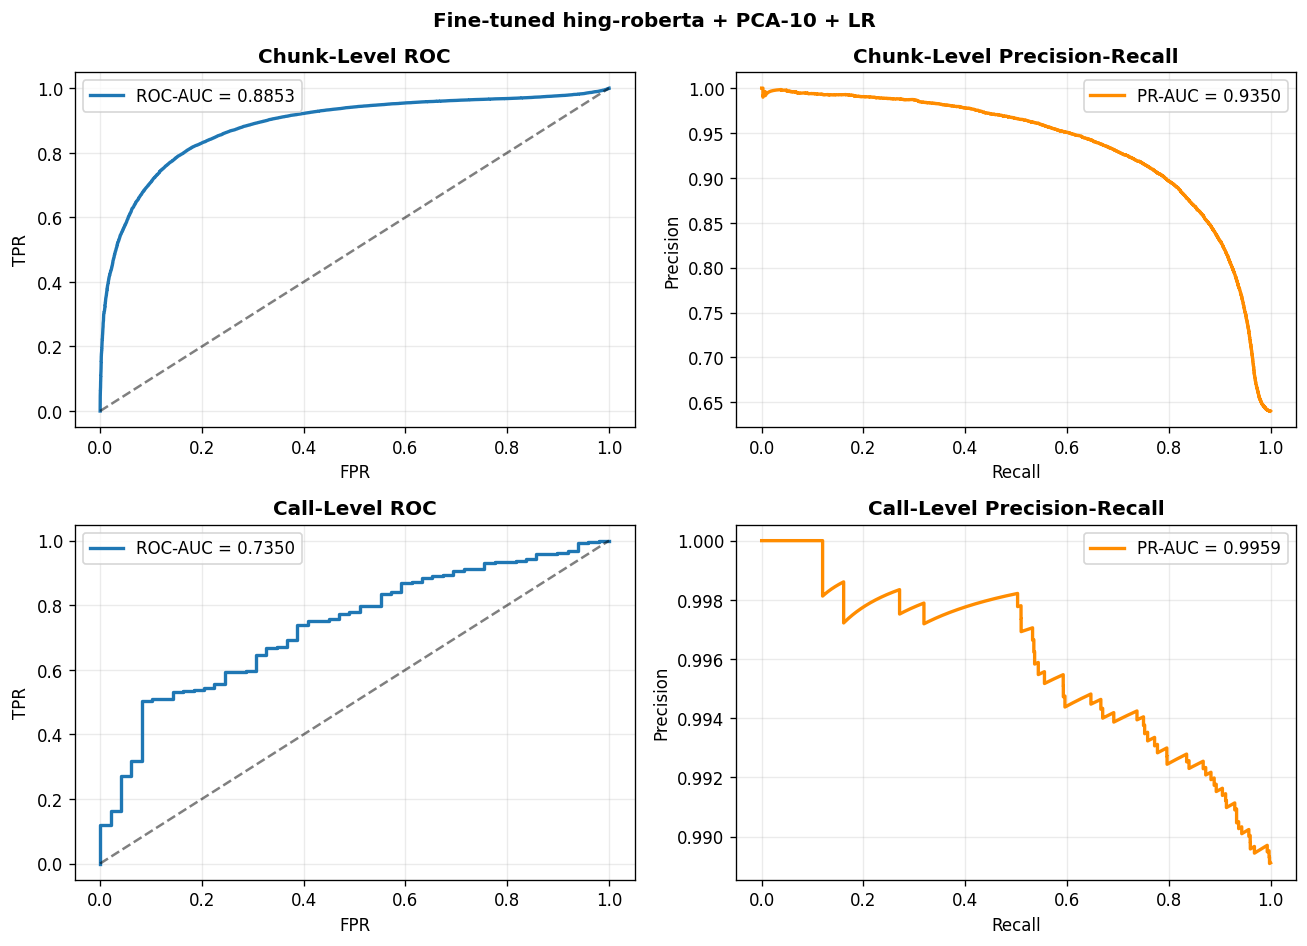


>>> Reference only: transformer's own softmax head (768-d, no PCA) - NOT the submitted model


HELD-OUT TEST RESULTS - Fine-tuned hing-roberta (raw head, reference)
Chunk-Level -> F1: 0.8568 | Prec: 0.8304 | Rec: 0.8848 | FPR: 0.3217 | ROC-AUC: 0.8793 | PR-AUC: 0.9321
Call-Level  -> F1: 0.9710 | Prec: 0.9904 | Rec: 0.9524 | FPR: 0.8367 | ROC-AUC: 0.74 | PR-AUC: 0.9960
Early Alert -> Median Time-to-Detection: 48.0s | thresholds {'tau_review': 0.0009, 'tau_alert': 0.0011, 'tau_velocity': 0.1496}
Extra       -> {'val_f1_at_tau_alert': 0.8734, 'test_legit_calls': 49.0, 'test_fraud_calls': 4450.0, 'fraud_calls_alerted_pct': 95.236, 'median_alert_lead_before_label_flip_sec': 0.0}


In [13]:
def calibrate_thresholds(val_scores, yv):
    best_f1, best_tau = -1.0, float(np.median(val_scores))
    for tau in np.quantile(val_scores, np.linspace(0.05, 0.99, 180)):
        f = f1_score(yv, (val_scores >= tau).astype(np.int8), zero_division=0)
        if f > best_f1:
            best_f1, best_tau = float(f), float(tau)
    tau_velocity = float(np.percentile(np.abs(np.diff(val_scores)), 95))
    return {"tau_review": 0.8 * best_tau, "tau_alert": best_tau, "tau_velocity": tau_velocity, "val_f1": best_f1}

def reasoning_engine(meta, scores, th):
    res = meta[["conversation_uid", "domain", "chunk_timestamp", "y"]].copy()
    res["score"] = scores
    same_call = res["conversation_uid"] == res["conversation_uid"].shift(1)
    res["risk_velocity"] = np.where(same_call, res["score"] - res["score"].shift(1), 0.0)
    alert = (res["score"] >= th["tau_alert"]) | ((res["score"] >= th["tau_review"]) & (res["risk_velocity"] >= th["tau_velocity"]))
    review = (~alert) & (res["score"] >= th["tau_review"])
    res["alert_level"] = np.where(alert, "ALERT", np.where(review, "REVIEW", "NORMAL"))
    res["pred"] = alert.astype(np.int8)
    return res

def evaluate(model_name, val_scores, test_scores, n_features, save=True):
    th = calibrate_thresholds(val_scores, y_val)
    s = reasoning_engine(test_df, test_scores, th)
    yt, yp = s["y"].to_numpy(), s["pred"].to_numpy()
    tn, fp, fn, tp = confusion_matrix(yt, yp, labels=[0, 1]).ravel()
    chunk = {"chunk_f1": f1_score(yt, yp, zero_division=0), "chunk_precision": precision_score(yt, yp, zero_division=0),
             "chunk_recall": recall_score(yt, yp, zero_division=0), "chunk_fpr": fp / max(fp + tn, 1),
             "chunk_roc_auc": roc_auc_score(yt, s["score"]), "chunk_pr_auc": average_precision_score(yt, s["score"])}
    calls = s.groupby("conversation_uid", sort=False).agg(y_true=("y", "last"), max_score=("score", "max"), any_alert=("pred", "max"))
    ctn, cfp, cfn, ctp = confusion_matrix(calls["y_true"], calls["any_alert"], labels=[0, 1]).ravel()
    caught = s[(s["y"] == 1) & (s["pred"] == 1)].groupby("conversation_uid")["chunk_timestamp"].min()
    flip = s[s["y"] == 1].groupby("conversation_uid")["chunk_timestamp"].min()
    any_alert_ts = s[s["pred"] == 1].groupby("conversation_uid")["chunk_timestamp"].min()
    lead = (flip - any_alert_ts.reindex(flip.index)).dropna()
    call = {"call_f1": f1_score(calls["y_true"], calls["any_alert"], zero_division=0),
            "call_precision": precision_score(calls["y_true"], calls["any_alert"], zero_division=0),
            "call_recall": recall_score(calls["y_true"], calls["any_alert"], zero_division=0),
            "call_fpr": cfp / max(cfp + ctn, 1),
            "call_roc_auc": roc_auc_score(calls["y_true"], calls["max_score"]) if calls["y_true"].nunique() > 1 else float("nan"),
            "call_pr_auc": average_precision_score(calls["y_true"], calls["max_score"]),
            "median_ttd_seconds": float(caught.median()) if len(caught) else None}
    r4 = lambda d: {k: (None if v is None or (isinstance(v, (float, np.floating)) and np.isnan(v)) else round(float(v), 4)) for k, v in d.items()}
    results = {"model_name": model_name, "pca_dimensions": int(n_features),
               "thresholds": r4({k: th[k] for k in ("tau_review", "tau_alert", "tau_velocity")}),
               "chunk_level": r4(chunk), "call_level": r4(call),
               "extra": r4({"val_f1_at_tau_alert": th["val_f1"], "test_legit_calls": int((calls["y_true"] == 0).sum()),
                            "test_fraud_calls": int((calls["y_true"] == 1).sum()),
                            "fraud_calls_alerted_pct": 100 * float(calls.loc[calls["y_true"] == 1, "any_alert"].mean()),
                            "median_alert_lead_before_label_flip_sec": float(lead.median()) if len(lead) else None})}
    print("=" * 74)
    print(f"HELD-OUT TEST RESULTS - {model_name}")
    print("=" * 74)
    c, k = results["chunk_level"], results["call_level"]
    print(f"Chunk-Level -> F1: {c['chunk_f1']:.4f} | Prec: {c['chunk_precision']:.4f} | Rec: {c['chunk_recall']:.4f} | FPR: {c['chunk_fpr']:.4f} | ROC-AUC: {c['chunk_roc_auc']:.4f} | PR-AUC: {c['chunk_pr_auc']:.4f}")
    print(f"Call-Level  -> F1: {k['call_f1']:.4f} | Prec: {k['call_precision']:.4f} | Rec: {k['call_recall']:.4f} | FPR: {k['call_fpr']:.4f} | ROC-AUC: {k['call_roc_auc']} | PR-AUC: {k['call_pr_auc']:.4f}")
    print(f"Early Alert -> Median Time-to-Detection: {k['median_ttd_seconds']}s | thresholds {results['thresholds']}")
    print(f"Extra       -> {results['extra']}")
    if save:
        with open(MODEL_OUT_DIR / f"{MODEL_SLUG}_metrics.json", "w", encoding="utf-8") as f:
            json.dump(results, f, indent=2)
        fig, ax = plt.subplots(2, 2, figsize=(11, 8))
        for row, (yy, ss, lvl) in enumerate([(yt, s["score"], "Chunk"), (calls["y_true"], calls["max_score"], "Call")]):
            fpr_c, tpr_c, _ = roc_curve(yy, ss); pr_c, rc_c, _ = precision_recall_curve(yy, ss)
            ax[row, 0].plot(fpr_c, tpr_c, lw=2, label=f"ROC-AUC = {roc_auc_score(yy, ss):.4f}"); ax[row, 0].plot([0, 1], [0, 1], "k--", alpha=.5)
            ax[row, 0].set_title(f"{lvl}-Level ROC", fontweight="bold"); ax[row, 0].set_xlabel("FPR"); ax[row, 0].set_ylabel("TPR"); ax[row, 0].legend()
            ax[row, 1].plot(rc_c, pr_c, lw=2, color="darkorange", label=f"PR-AUC = {average_precision_score(yy, ss):.4f}")
            ax[row, 1].set_title(f"{lvl}-Level Precision-Recall", fontweight="bold"); ax[row, 1].set_xlabel("Recall"); ax[row, 1].set_ylabel("Precision"); ax[row, 1].legend()
        fig.suptitle(model_name, fontweight="bold"); plt.tight_layout()
        fig.savefig(MODEL_OUT_DIR / f"{MODEL_SLUG}_curves.png", dpi=200); plt.show()
    return results, s, th

short = BEST_BACKBONE.split("/")[-1]
MODEL_NAME = f"Fine-tuned {short} + PCA-{N_COMPONENTS} + LR"
print(">>> OFFICIAL MODEL (<= 50 features after PCA)")
results, test_stream, THRESHOLDS = evaluate(MODEL_NAME, score_val, score_test, n_features=N_COMPONENTS, save=True)
print("\n>>> Reference only: transformer's own softmax head (768-d, no PCA) - NOT the submitted model")
ref_results, _, _ = evaluate(f"Fine-tuned {short} (raw head, reference)", val_df["tf_prob"].to_numpy(), test_df["tf_prob"].to_numpy(),
                             n_features=FEAT["head"].shape[1], save=False)

## Section 10: Save Everything for Reuse (no retraining) + Reload Check
* `outputs/models/finetuned_transformer/` — fine-tuned weights (fp16 `safetensors`) + tokenizer (**large: kept out of git**, stored as Kaggle notebook output + local copy).
* `outputs/models/finetuned_transformer_pca_head.joblib` — scaler, PCA, classifier, one-hot encoder, imputation values.
* `outputs/models/finetuned_transformer_config.json` — backbone, truncation, thresholds, bake-off & PCA-grid results.

`load_fraud_detector()` + `predict_fraud()` below are all the live demo needs.

In [14]:
joblib.dump({"scaler": SCALER, "pca": PCA_MODEL, "classifier": CLASSIFIER, "ohe": OHE, "pace_median": PACE_MEDIAN,
             "conf_median": CONF_MEDIAN, "top_dominant_emotions": TOP_DOM, "top_secondary_emotions": TOP_SEC,
             "n_components": N_COMPONENTS, "n_raw_features": N_RAW_FEATURES},
            MODEL_OUT_DIR / f"{MODEL_SLUG}_pca_head.joblib")
config = {"model_name": MODEL_NAME, "backbone": BEST_BACKBONE, "weights_dir": str(FINAL_MODEL_DIR), "max_len": MAX_LEN,
          "head_tokens": HEAD_TOKENS, "thresholds": THRESHOLDS, "pca_components": N_COMPONENTS, "n_raw_features": N_RAW_FEATURES,
          "bakeoff": bakeoff_df.to_dict(orient="records"), "pca_grid": grid, "training": {k: full_res[k] for k in ("world_size", "train_runtime_sec", "global_step", "best_metric")},
          "inputs": MODEL_INPUT_COLS, "label": "per-chunk final_verdict (YES=1)", "random_seed": RANDOM_SEED, "smoke": SMOKE}
with open(MODEL_OUT_DIR / f"{MODEL_SLUG}_config.json", "w", encoding="utf-8") as f:
    json.dump(config, f, indent=2, default=str)

def load_fraud_detector(model_dir=FINAL_MODEL_DIR, head_path=MODEL_OUT_DIR / f"{MODEL_SLUG}_pca_head.joblib",
                        config_path=MODEL_OUT_DIR / f"{MODEL_SLUG}_config.json"):
    return {"model_dir": Path(model_dir), "head": joblib.load(head_path), "config": json.load(open(config_path))}

def predict_fraud(detector, texts, audio_jsons, timestamps):
    # P(fraud) for a list of chunks (cumulative text, audio-analysis JSON string, timestamp in seconds).
    h = detector["head"]
    df = clean_split(pd.DataFrame({"conversation_uid": "live", "domain": "live", "chunk_timestamp": timestamps,
                                   "final_verdict": "NO", "cumulative_text": texts, "cumulative_audio_analysis_json": audio_jsons}))
    _, feat = transformer_scores(detector["model_dir"], df["text"].tolist())
    a = pd.DataFrame({"dominant_emotion": df["dominant_emotion"].where(df["dominant_emotion"].isin(h["top_dominant_emotions"]), "Other"),
                      "secondary_emotion": df["secondary_emotion"].where(df["secondary_emotion"].isin(h["top_secondary_emotions"]), "Other"),
                      "pace_num": df["pace_num"].fillna(h["pace_median"]), "confidence_score": df["confidence_score"].fillna(h["conf_median"]),
                      "chunk_timestamp": df["chunk_timestamp"]})
    X = np.hstack([feat, h["ohe"].transform(a[["dominant_emotion", "secondary_emotion"]]),
                   a[["pace_num", "confidence_score", "chunk_timestamp"]].to_numpy(np.float32)]).astype(np.float32)
    return h["classifier"].predict_proba(h["pca"].transform(h["scaler"].transform(X)))[:, 1]

# Reload check: fresh load from disk must reproduce the validation scores
det = load_fraud_detector()
idx = np.random.default_rng(0).choice(len(val_df), size=min(300, len(val_df)), replace=False)
sub = val_df.iloc[idx]
re_scores = predict_fraud(det, sub["text"].tolist(), sub["audio_json"].tolist(), sub["chunk_timestamp"].tolist())
max_diff = float(np.max(np.abs(re_scores - score_val[idx])))
print(f"Reload check: max |difference| over {len(idx)} validation chunks = {max_diff:.2e}")
assert max_diff < 1e-2, "Reloaded detector does not reproduce the scores"
print("Reload check passed.")
for f in sorted(MODEL_OUT_DIR.glob(f"{MODEL_SLUG}*")):
    size = sum(p.stat().st_size for p in f.glob("*")) if f.is_dir() else f.stat().st_size
    print(f"  {f}  ({size/1e6:.1f} MB)")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (526 > 512). Running this sequence through the model will result in indexing errors


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Reload check: max |difference| over 300 validation chunks = 1.69e-03
Reload check passed.
  outputs/models/finetuned_transformer  (573.2 MB)
  outputs/models/finetuned_transformer_config.json  (0.0 MB)
  outputs/models/finetuned_transformer_curves.png  (0.2 MB)
  outputs/models/finetuned_transformer_metrics.json  (0.0 MB)
  outputs/models/finetuned_transformer_pca_head.joblib  (0.1 MB)
  outputs/models/finetuned_transformer_training_curve.png  (0.1 MB)


## Section 11: Comparison with the Unsupervised Team Models
Any `*_metrics.json` already in `outputs/models/` (from merged teammate PRs) is listed next to this model.

In [15]:
rows = []
for f in sorted(MODEL_OUT_DIR.glob("*_metrics.json")):
    try:
        m = json.load(open(f))
        rows.append({"model": m["model_name"], **{k: m["chunk_level"].get(k) for k in ("chunk_f1", "chunk_roc_auc", "chunk_pr_auc", "chunk_fpr")},
                     **{k: m["call_level"].get(k) for k in ("call_f1", "call_roc_auc", "median_ttd_seconds")}})
    except Exception as e:
        print("skip", f.name, e)
comparison = pd.DataFrame(rows).sort_values("chunk_roc_auc", ascending=False)
print(comparison.to_string(index=False))

                                model  chunk_f1  chunk_roc_auc  chunk_pr_auc  chunk_fpr  call_f1  call_roc_auc  median_ttd_seconds
Fine-tuned hing-roberta + PCA-10 + LR    0.8637         0.8853         0.935     0.3357   0.9788         0.735                48.0
